# Prova Prática — Ciência de Dados com Python

**Nome:**______________________  **Data:** ____/____/____

## Instruções
1. Baixe o arquivo **vendas_loja.csv** e faça upload no Google Colab (ícone de pasta 📁 na barra lateral).
2. Resolva as **10 questões** nas células indicadas, escrevendo seu código.
3. O notebook deve rodar do início ao fim sem erros (use **Runtime → Run all** antes de entregar).
4. Cada questão vale **1,0 ponto**.

## Dataset: vendas_loja.csv
Registros de vendas de uma loja de eletrônicos, com as colunas:
`produto`, `categoria`, `preco`, `quantidade`, `vendedor`, `regiao`, `mes`

> ⚠️ Atenção: o dataset contém **valores ausentes e linhas duplicadas de propósito** — você vai precisar tratá-los nas questões 4 e 5!


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
## Questão 1 — Importação e exploração (1,0 pt)
Importe o arquivo `vendas_loja.csv` e mostre:
- as 5 primeiras linhas (`head`)
- o tamanho do dataset (`shape`)
- as informações gerais (`info`)

In [2]:
# Q1 - seu código aqui
df = pd.read_csv('/content/vendas_loja (5).csv')

# Exibir as 5 primeiras linhas
display(df.head())

# Exibir o tamanho do dataset
print(f"Tamanho do dataset: {df.shape}")

# Exibir informações gerais
print("\nInformações gerais do dataset:")
df.info()

,produto,categoria,preco,quantidade,vendedor,regiao,mes
0,Caixa de Som,Áudio,110.0,10.0,Carla,Leste,Abr
1,Monitor,Informática,900.0,10.0,Carla,Oeste,Abr
2,Cabo HDMI,Acessórios,30.0,3.0,Diego,Sul,Fev
3,Webcam,Informática,150.0,7.0,Ana,Norte,Mar
4,Caixa de Som,Áudio,110.0,1.0,Diego,Oeste,Abr


Tamanho do dataset: (122, 7)

Informações gerais do dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   produto     122 non-null    object 
 1   categoria   122 non-null    object 
 2   preco       118 non-null    float64
 3   quantidade  116 non-null    float64
 4   vendedor    122 non-null    object 
 5   regiao      122 non-null    object 
 6   mes         122 non-null    object 
dtypes: float64(2), object(5)
memory usage: 6.8+ KB


## Questão 2 — Explorando com describe (1,0 pt)
Mostre as estatísticas das colunas numéricas com `describe()` e escreva **uma frase** interpretando qual é a média de `preco` do dataset.

In [3]:
# Q2 - seu código aqui
display(df.describe())

mean_price = df['preco'].mean()
print(f"\nInterpretação: A média da coluna preco é de aproximadamente R$ {mean_price:.2f}, representando o valor médio cobrado pelos produtos registrados no conjunto de dados.")

,preco,quantidade
count,118.000000,116.000000
mean,175.805085,5.267241
std,239.386654,2.979226
min,25.000000,1.000000
25%,40.000000,3.000000
50%,110.000000,5.000000
75%,150.000000,8.000000
max,900.000000,10.000000



Interpretação: A média da coluna preco é de aproximadamente R$ 175.81, representando o valor médio cobrado pelos produtos registrados no conjunto de dados.


## Questão 3 — NumPy (1,0 pt)
Transforme a coluna `preco` em um array NumPy e calcule e imprima:
- a média
- o maior preço
- o menor preço
- a quantidade de preços registrados (`size`)

In [4]:
# Q3 - seu código aqui
# Conversão para array NumPy
array_precos = df['preco'].to_numpy()

# Cálculo das métricas usando funções do numpy que lidam com possíveis NaNs
media_numpy = np.nanmean(array_precos)
maior_numpy = np.nanmax(array_precos)
menor_numpy = np.nanmin(array_precos)
tamanho_numpy = array_precos.size

print(f"Média dos preços: {media_numpy:.2f}")
print(f"Maior preço: {maior_numpy:.2f}")
print(f"Menor preço: {menor_numpy:.2f}")
print(f"Quantidade de preços registrados (tamanho do array): {tamanho_numpy}")

Média dos preços: 175.81
Maior preço: 900.00
Menor preço: 25.00
Quantidade de preços registrados (tamanho do array): 122


## Questão 4 — Valores ausentes (1,0 pt)
a) Conte quantos valores ausentes existem em **cada coluna**.
b) Preencha os ausentes de `preco` com a **média** da coluna e os de `quantidade` com o valor **0**.
c) Mostre de novo a contagem de ausentes para provar que não sobrou nenhum.
> Justifique em uma frase: por que preencher `quantidade` com 0 e não com a média?

In [5]:
# Q4 - seu código aqui
# a) Contar valores ausentes antes do preenchimento
print("Quantidade de valores ausentes por coluna antes:")
print(df.isnull().sum())
print("\n" + "="*40 + "\n")

# b) Preencher os valores nulos
df['preco'] = df['preco'].fillna(df['preco'].mean())
df['quantidade'] = df['quantidade'].fillna(0)

# c) Mostrar novamente a contagem de ausentes
print("Quantidade de valores ausentes por coluna após:")
print(df.isnull().sum())
print("\n" + "="*40 + "\n")

# Justificativa
print("Justificativa: Faz sentido preencher 'quantidade' com 0 porque a ausência de registro geralmente indica que nenhuma unidade foi vendida daquele item, enquanto preencher com a média distorceria as transações reais ao sugerir vendas fracionadas ou artificiais.")

Quantidade de valores ausentes por coluna antes:
produto       0
categoria     0
preco         4
quantidade    6
vendedor      0
regiao        0
mes           0
dtype: int64


Quantidade de valores ausentes por coluna após:
produto       0
categoria     0
preco         0
quantidade    0
vendedor      0
regiao        0
mes           0
dtype: int64


Justificativa: Faz sentido preencher 'quantidade' com 0 porque a ausência de registro geralmente indica que nenhuma unidade foi vendida daquele item, enquanto preencher com a média distorceria as transações reais ao sugerir vendas fracionadas ou artificiais.


## Questão 5 — Duplicados (1,0 pt)
Verifique quantas linhas duplicadas existem no DataFrame e remova-as, mantendo a primeira ocorrência. Mostre o `shape` antes e depois.

In [6]:
# Q5 - seu código aqui
shape_antes = df.shape
duplicados_count = df.duplicated().sum()

print(f"Quantidade de linhas duplicadas identificadas: {duplicados_count}")
print(f"Shape antes da remoção: {shape_antes}")

# Removendo duplicados e mantendo o primeiro
df = df.drop_duplicates(keep='first')
shape_depois = df.shape

print(f"Shape depois da remoção: {shape_depois}")

Quantidade de linhas duplicadas identificadas: 3
Shape antes da remoção: (122, 7)
Shape depois da remoção: (119, 7)


## Questão 6 — Criando coluna calculada (1,0 pt)
Crie a coluna `total`, que deve ser `preco` × `quantidade` (valor total de cada venda). Mostre o DataFrame com as colunas `produto`, `preco`, `quantidade` e `total`.

In [7]:
# Q6 - seu código aqui
# Criando a nova coluna multiplicando as colunas preco e quantidade
df['total'] = df['preco'] * df['quantidade']

# Exibindo as colunas solicitadas
display(df[['produto', 'preco', 'quantidade', 'total']].head())

,produto,preco,quantidade,total
0,Caixa de Som,110.0,10.0,1100.0
1,Monitor,900.0,10.0,9000.0
2,Cabo HDMI,30.0,3.0,90.0
3,Webcam,150.0,7.0,1050.0
4,Caixa de Som,110.0,1.0,110.0


## Questão 7 — Filtros com condição (1,0 pt)
Filtre e mostre apenas as vendas cujo `total` seja **maior ou igual a 500**. Quantas vendas são essas?

In [8]:
# Q7 - seu código aqui
# Filtro para vendas com total maior ou igual a 500
vendas_filtro = df[df['total'] >= 500]

display(vendas_filtro)
print(f"Total de vendas que atingiram ou superaram R$ 500: {len(vendas_filtro)} vendas.")

,produto,categoria,preco,quantidade,vendedor,regiao,mes,total
0,Caixa de Som,Áudio,110.000000,10.0,Carla,Leste,Abr,1100.000000
1,Monitor,Informática,900.000000,10.0,Carla,Oeste,Abr,9000.000000
3,Webcam,Informática,150.000000,7.0,Ana,Norte,Mar,1050.000000
5,HD Externo,Armazenamento,350.000000,4.0,Carla,Oeste,Jan,1400.000000
7,Caixa de Som,Áudio,110.000000,5.0,Diego,Leste,Mai,550.000000
9,Webcam,Informática,150.000000,7.0,Carla,Leste,Mar,1050.000000
10,Monitor,Informática,900.000000,4.0,Ana,Oeste,Mai,3600.000000
15,Webcam,Informática,150.000000,10.0,Bruno,Oeste,Fev,1500.000000
16,Teclado,Informática,120.000000,9.0,Bruno,Sul,Mar,1080.000000
20,Webcam,Informática,150.000000,10.0,Diego,Oeste,Abr,1500.000000


Total de vendas que atingiram ou superaram R$ 500: 48 vendas.


## Questão 8 — Filtro com duas condições (1,0 pt)
Filtre e mostre as vendas da **região 'Sul'** com **quantidade maior que 5**. Use o operador `&` e não esqueça dos parênteses!
> Escreva o filtro na forma: `df[(condição1) & (condição2)]`

In [9]:
# Q8 - seu código aqui
# Aplicando filtro com as duas condições solicitadas
filtro_sul_maior_5 = df[(df['regiao'] == 'Sul') & (df['quantidade'] > 5)]

display(filtro_sul_maior_5)

,produto,categoria,preco,quantidade,vendedor,regiao,mes,total
16,Teclado,Informática,120.000000,9.0,Bruno,Sul,Mar,1080.000000
26,HD Externo,Armazenamento,350.000000,9.0,Carla,Sul,Mar,3150.000000
38,Teclado,Informática,120.000000,10.0,Ana,Sul,Fev,1200.000000
41,Teclado,Informática,120.000000,8.0,Elisa,Sul,Mai,960.000000
69,Pen Drive,Acessórios,175.805085,7.0,Ana,Sul,Jan,1230.635593
74,Cabo HDMI,Acessórios,30.000000,6.0,Bruno,Sul,Mai,180.000000
75,HD Externo,Armazenamento,350.000000,8.0,Carla,Sul,Mar,2800.000000
82,Cabo HDMI,Acessórios,30.000000,9.0,Carla,Sul,Mar,270.000000
88,Cabo HDMI,Acessórios,30.000000,10.0,Ana,Sul,Mar,300.000000
92,Webcam,Informática,150.000000,7.0,Ana,Sul,Mar,1050.000000


## Questão 9 — Agrupamento com groupby (1,0 pt)
a) Use `groupby` para mostrar o **total vendido por categoria** (soma da coluna `total`).
b) Monte um resumo com `.agg()` mostrando, por categoria: soma das vendas, ticket médio e quantidade de vendas (use `reset_index()`).
c) Escreva **uma frase**: qual categoria vendeu mais?

In [10]:
# Q9 - seu código aqui
# a) Total vendido por categoria
total_categoria = df.groupby('categoria')['total'].sum()
print("Total vendido por categoria:")
print(total_categoria)
print("\n" + "="*40 + "\n")

# b) Resumo com .agg() contendo soma, média e contagem
resumo_vendas = df.groupby('categoria')['total'].agg(
    soma_vendas='sum',
    ticket_medio='mean',
    quantidade_vendas='count'
).reset_index()

display(resumo_vendas)

# c) Frase explicativa identificando a categoria líder de vendas
categoria_lider = resumo_vendas.loc[resumo_vendas['soma_vendas'].idxmax()]['categoria']
print(f"\nFrase explicativa: A categoria que obteve o maior faturamento e vendeu mais foi '{categoria_lider}'.")

Total vendido por categoria:
categoria
Acessórios        6858.050847
Armazenamento    21350.000000
Informática      59470.000000
Áudio            16814.491525
Name: total, dtype: float64




,categoria,soma_vendas,ticket_medio,quantidade_vendas
0,Acessórios,6858.050847,185.352726,37
1,Armazenamento,21350.000000,1779.166667,12
2,Informática,59470.000000,1415.952381,42
3,Áudio,16814.491525,600.517554,28



Frase explicativa: A categoria que obteve o maior faturamento e vendeu mais foi 'Informática'.


## Questão 10 — Visualização (1,0 pt)
Crie **dois gráficos** e escreva uma frase interpretando cada um:
1. **Matplotlib**: gráfico de barras com o total vendido por categoria (com `title`, `xlabel` e `ylabel`).
2. **Seaborn**: `boxplot` da coluna `total` por `regiao` — existe alguma região com vendas fora da curva?

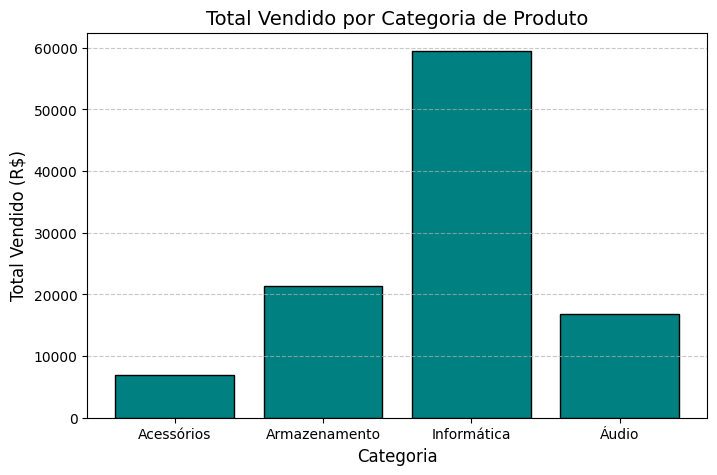

Interpretação: Este gráfico de barras permite comparar visualmente o faturamento total acumulado em cada categoria, facilitando a identificação dos setores mais relevantes financeiramente para o negócio.


In [11]:
# Q10 - gráfico 1 (Matplotlib)
vendas_por_cat = df.groupby('categoria')['total'].sum()

plt.figure(figsize=(8, 5))
plt.bar(vendas_por_cat.index, vendas_por_cat.values, color='teal', edgecolor='black')
plt.title('Total Vendido por Categoria de Produto', fontsize=14)
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Total Vendido (R$)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("Interpretação: Este gráfico de barras permite comparar visualmente o faturamento total acumulado em cada categoria, facilitando a identificação dos setores mais relevantes financeiramente para o negócio.")

/tmp/ipykernel_533/44518238.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='regiao', y='total', data=df, palette='Set3')


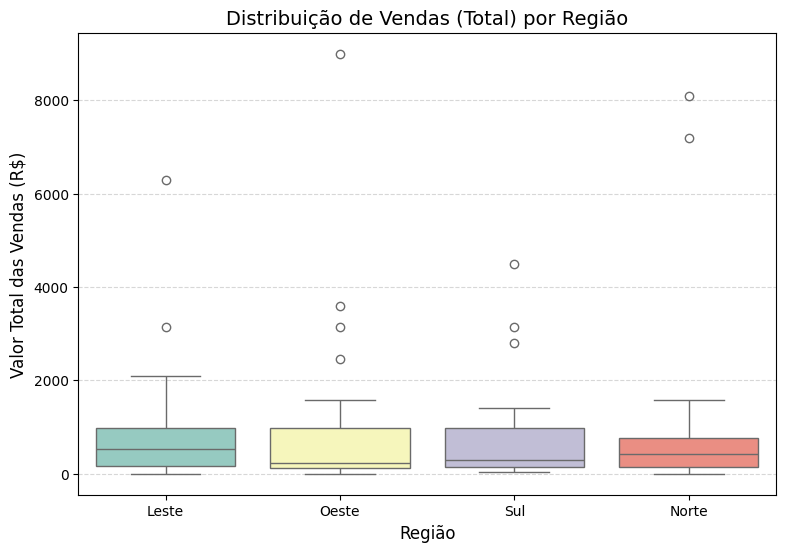

Interpretação: O boxplot exibe o intervalo de distribuição dos valores das vendas por região. Pontos situados além das hastes de limite ('whiskers') revelam a existência de valores discrepantes (outliers), permitindo avaliar onde estão as compras mais caras de forma atípica.


In [12]:
# Q10 - gráfico 2 (Seaborn)
plt.figure(figsize=(9, 6))
sns.boxplot(x='regiao', y='total', data=df, palette='Set3')
plt.title('Distribuição de Vendas (Total) por Região', fontsize=14)
plt.xlabel('Região', fontsize=12)
plt.ylabel('Valor Total das Vendas (R$)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

print("Interpretação: O boxplot exibe o intervalo de distribuição dos valores das vendas por região. Pontos situados além das hastes de limite ('whiskers') revelam a existência de valores discrepantes (outliers), permitindo avaliar onde estão as compras mais caras de forma atípica.")

---
## Entrega
1. Rode tudo: **Runtime → Run all** e confira que não há erros.
2. Baixe o notebook: **File → Download → Download .ipynb**.
3. Envie o arquivo `.ipynb` pelo link indicado pelo professor.

**Boa prova! 🚀**